# 농기계 고장·정비 기록 문서 분류
### 짧은 수리 기록을 읽고 정비 유형을 자동으로 나누기 — TF-IDF(단어 vs 글자) + 분류 모델

**환경:** Google Colab (인터넷 연결 필요)
**준비물 (파일 2개)**
| 파일 | 내용 |
|---|---|
| 수리 내역 `.csv` 파일 | 농기계 임대사업소 수리 기록 1,412건 (수리일자, 기종관리번호, **수리내역**, 금액, **비고**, 임대사업장 …) |
| `repair_labels.csv` | 기록 번호(ID)별 **정답 정비 유형** (원래 파일에는 정답이 없어서 따로 만든 파일) |



## 오늘의 상황
> 농기계 임대사업소에는 해마다 수백 건의 수리 기록이 쌓입니다. 그런데 기록은 `정비`, `밸트교환`, `로타리칼 12개`처럼 **짧고 제각각**입니다.
> 기록을 **정비 유형**별로 자동으로 나누면, 어떤 정비에 돈과 시간이 많이 드는지 한눈에 볼 수 있습니다.

## 분류할 정비 유형 (5개)
| 유형 | 예 |
|---|---|
| 소모품 교환 | 엔진오일, V벨트, 필터, 배터리, 점화플러그, 스펀지, 타이어·튜브 |
| 작업날 교환 | 로터리칼, 경운날, 예취날, 두둑칼, 보습, 쟁기날, 타인 (날을 고정하는 볼트 포함) |
| 부품 수리·교체 | 베어링, 유압호스·모터, 체인, 궤도, 클러치·케이블, 엔진·버킷 교환 |
| 일반 정비·점검 | `정비`, 오일 보충, 기화기 정비, 정기 점검 (무엇을 바꿨는지 적혀 있지 않은 기록) |
| 고장 증상 | 작동불량, 시동불량, 정지, 파손 (고친 내용 없이 증상만 적힌 기록) |

## 실습 진행 과정
| 단계 | 할 일 | 산출물 |
|---|---|---|
| 0. 준비 | 설치, 파일 2개 읽기 | 원본 표 |
| 1. 텍스트 전처리 | 수리내역+비고 합치기 → **표기 통일**·숫자·기호 정리 → 단어 나누기 | 처리 전/후 비교 |
| 2. 정제 데이터셋 | 정답 붙이기 → 중복 문서 제거 → 유형 분포·유형별 금액 | `repair_dataset.csv` |
| 3. 텍스트 분석 | 학습/평가 나누기 → **단어 단위 vs 글자 단위** TF-IDF × 모델 2개 비교 | 최종 모델 |
| 4. 분석 결과 | 성적표, 혼동 행렬, 틀린 문서, 연도별 변화, **새 기록 넣어 보기** | 그래프, `predictions.csv` |
| 정리 | 한계, 연습 문제 | — |

> **실행 방법:** 셀을 클릭하고 `Shift + Enter`. 반드시 **위에서부터 순서대로** 실행하세요.
> ✏️ 표시가 있는 곳은 **직접 바꿔 볼 수 있는 부분**입니다.

---
## 0. 준비
| 도구 | 하는 일 |
|---|---|
| `kiwipiepy` | 한국어 형태소 분석기 Kiwi (단어 나누기) |
| `koreanize-matplotlib` | 그래프에 한글 글꼴(나눔고딕) 설정 |
| `scikit-learn` | TF-IDF, 분류 모델, 평가 (Colab에 기본 설치) |

In [1]:
# 도구 설치 (처음 한 번만 실행)
# !     : 파이썬 코드가 아니라 리눅스 명령어를 실행하라는 표시
# -q    : 설치 과정 메시지를 짧게 줄여서 보여 줌
!pip install -q kiwipiepy koreanize-matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 MB 11.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 81.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 78.4 MB/s eta 0:00:00


> 🔧 다음 셀에서 `PIL` 관련 `ImportError`가 나면: 메뉴 **런타임 → 세션 다시 시작** 후 설치 셀은 건너뛰고 다음 셀부터 실행하세요.

Colab 왼쪽 **📁 파일 창**에 **수리 내역 `.csv` 파일**과 **`repair_labels.csv`** 를 끌어다 놓으세요.

### 💡 `encoding="cp949"`는 왜 쓰나요?
한글 파일은 저장 방식(인코딩)이 두 가지가 흔합니다. 요즘 파일은 대부분 `utf-8`이지만, 공공기관·엑셀에서 내려받은 파일은 `cp949`(완성형 한글)인 경우가 많습니다. 이 파일은 `cp949`라서, 그냥 읽으면 `UnicodeDecodeError`가 납니다.

In [2]:
import glob                 # 파일 이름을 패턴(예: *.csv)으로 찾는 도구
import pandas as pd         # 표(DataFrame)를 다루는 도구

# 정답 파일 읽기 → 열 2개(ID, 유형)짜리 표 (utf-8-sig: 엑셀용 utf-8)
labels = pd.read_csv("repair_labels.csv", encoding="utf-8-sig")

# 지금 폴더의 .csv 파일 중 정답 파일과 이 실습에서 만드는 파일이 아닌 것 = 수리 내역 파일
#   (다시 실행할 때 실습 결과 파일을 원본으로 잘못 고르지 않게 이름을 빼 둠)
MY_FILES = {"repair_labels.csv", "repair_dataset.csv", "predictions.csv"}
raw_path = [p for p in glob.glob("*.csv") if p not in MY_FILES][0]

# 수리 내역 파일 읽기 (encoding="cp949": 이 파일의 한글 저장 방식)
raw = pd.read_csv(raw_path, encoding="cp949")

# 원래 줄 번호(0, 1, 2, …)를 기록 번호 ID로 사용 (정답 파일의 ID와 같은 번호)
raw["ID"] = raw.index

print("수리 내역 파일:", raw_path, "/ 행 수:", len(raw))
print("정답 파일 행 수:", len(labels))

# 앞 5줄 보기
raw.head()

수리 내역 파일: 충청북도 충주시_농기계임대사업장 농기계수리내역_20260831.csv / 행 수: 1412
정답 파일 행 수: 1380


,수리일자,기종관리번호,수리내역,금액,비고,임대사업장,데이터기준일자,ID
0,2009-05-07,56,[임대보류]교육용농기계,0,NaN,농업기술센터,2026-08-31,0
1,2011-04-20,83,[수리중]로터리 베어링 파손,0,NaN,농업기술센터,2026-08-31,1
2,2013-04-04,211,[수리중]4월4일 이광수사용중 축고장,0,NaN,농업기술센터,2026-08-31,2
3,2013-06-21,72,[수리중]끈 안끈어짐,0,NaN,대소원 임대사업소,2026-08-31,3
4,2009-04-21,274,작동불량,150000,NaN,농업기술센터,2026-08-31,4


---
## 1. 텍스트 데이터 전처리

### 💡 이 데이터의 특징
| 특징 | 예 | 처리 방법 |
|---|---|---|
| 기록이 **아주 짧음** (평균 7글자) | `정비`, `작동불량` | 비고 열을 합쳐 단서 늘리기 |
| 비고가 비어 있는 기록이 많음 (약 42%) | `NaN` | 빈 글자로 바꾼 뒤 합치기 |
| **같은 부품을 여러 이름으로** 씀 | `밸트/벨트`, `밧데리/축전지/배터리`, `로타리/로터리` | 표기 통일 사전 |
| 수량·규격·부품 번호 | `12개`, `2EA`, `B58`, `6307` | 수량은 단위까지 지우고, 번호도 지우기 (벨트 규격 `B-58`은 `벨트`로 바꿈) |
| 처리 상태 표시 | `[수리중]`, `[폐기]` | 대괄호 부분 지우기 |
| 기록에 사람 이름이 들어간 경우 | `○○○님` | `…님` 지우기 |

### 1-1. 수리내역과 비고 합치기

In [3]:
# 비고가 빈 칸(NaN)이면 빈 글자 ""로 바꾼 뒤, 수리내역과 한 칸 띄워 이어 붙이기
raw["원문"] = raw["수리내역"].fillna("") + " " + raw["비고"].fillna("")

# 합친 결과 5개 보기 (sample: 무작위로 고르기, random_state=3: 매번 같은 5개)
raw[["수리내역", "비고", "원문"]].sample(5, random_state=3)

,수리내역,비고,원문
717,로터리칼교환,로터리칼 12개,로터리칼교환 로터리칼 12개
818,엔진오일교환,NaN,엔진오일교환
1382,종자통1+ 파종구동바퀴 수리,종자통1 교환+ 파종기구동바퀴 바늘 수리,종자통1+ 파종구동바퀴 수리 종자통1 교환+ 파종기구동바퀴 바늘 수리
804,콤바인수리,0.콤비네이션 스위치1개0.끌어올림갈퀴조합5개0.6308DD(F) 5개0.아이들롤러...,콤바인수리 0.콤비네이션 스위치1개0.끌어올림갈퀴조합5개0.6308DD(F) 5개0...
69,죠인트불량,NaN,죠인트불량


### 1-2. 정제 함수: 표기 통일 + 숫자·기호 정리
**✏️ 표기 통일 사전 `NORM`**: 왼쪽 표현을 오른쪽 표현으로 바꿉니다. 데이터를 보다가 다른 표기를 발견하면 직접 추가해 보세요.

In [4]:
import re                   # 정규식(글자 패턴 찾기·바꾸기) 도구

# ✏️ 표기 통일 사전 {바꿀 표현: 통일할 표현}
NORM = {
    "밸트": "벨트", "밧데리": "배터리", "바테리": "배터리", "밧테리": "배터리", "축전지": "배터리", "춛전지": "배터리",
    "베아링": "베어링", "베어린": "베어링", "로타리": "로터리", "로터리발": "로터리날",
    "휠타": "필터", "휠터": "필터", "필타": "필터", "에이크리너": "에어클리너", "에어크리너": "에어클리너", "에어크린너": "에어클리너",
    "스폰치": "스펀지", "스폰지": "스펀지", "스펀치": "스펀지", "캬브레다": "기화기", "카브레다": "기화기",
    "죠인트": "조인트", "쪼인트": "조인트", "구리스": "그리스", "니뿔": "니플", "모타": "모터", "교한": "교환", "교체": "교환",
}

# 기록 하나 → 정리된 문서
def clean(text):
    text = re.sub(r"\[.*?\]", " ", text)                             # [수리중], [폐기] 같은 대괄호 부분 지우기 (.*? : 가장 짧게)
    text = re.sub(r"\S+님", " ", text)                                # '○○○님' 처럼 '님'으로 끝나는 말(사람 이름) 지우기
    text = re.sub(r"(?<![A-Za-z])(LB|B)\s*-?\s*\d+", " 벨트 ", text)  # 벨트 규격(B-58, LB-60) → '벨트'
    for old, new in NORM.items():                                     # 사전의 (바꿀 표현, 통일할 표현)을 하나씩 꺼내서
        text = text.replace(old, new)                                 # 글자 그대로 바꾸기
    text = re.sub(r"\d+\s*(개|종|리터|EA|ea)", " ", text)               # 수량(12개, 3종, 2EA) 지우기
    text = re.sub(r"[A-Za-z]*-?\d+[A-Za-z]*", " ", text)              # 숫자가 든 규격·부품 번호(6307, sa-124, B/R 앞 210) 지우기
    text = re.sub(r"[^가-힣A-Za-z]", " ", text)                        # 한글·영어가 아닌 글자(기호, 괄호, 마침표) → 공백
    text = re.sub(r"내용없음|완료", " ", text)                          # 뜻 없는 말 지우기
    return re.sub(r"\s+", " ", text).strip()                          # 여러 칸 공백을 한 칸으로, 앞뒤 공백 지우기

# 모든 기록에 함수 적용 → '문서' 열 만들기
raw["문서"] = raw["원문"].apply(clean)

# 처리 전/후 비교: 표기가 흔들리던 기록 5개
examples = raw[raw["원문"].str.contains("밸트|밧데리|로타리|B-58|베아링")].head(5)
examples[["원문", "문서"]]

,원문,문서
22,밸트불량,벨트불량
48,밸트불량,벨트불량
49,밸트불량,벨트불량
51,밸트불량,벨트불량
59,밸트불량,벨트불량


✅ **결과 확인:** `밸트 2개` → `벨트`, `밧데리` → `배터리`처럼 같은 부품이 **같은 이름**으로 바뀌었나요? 숫자와 `EA` 같은 단위가 사라졌나요?

### 1-3. 단어 나누기
TF-IDF에 넣을 **단어 목록**을 만듭니다. (3단계에서 **글자 단위** 방식과 비교합니다.)

| 남기는 품사 | 기호 | 예 |
|---|---|---|
| 명사 | NNG, NNP | `벨트`, `베어링`, `로터리` |
| 동사·형용사 | VV, VA | `바꾸`, `끊어지` |
| 어근 | XR | `불량`이 어근으로 나오기도 함 |
| 부사 | MAG | `안` |
| 외국어 | SL | `PTO`, `HST` |

In [5]:
from kiwipiepy import Kiwi   # 한국어 형태소 분석기
kiwi = Kiwi()                  # 분석기 준비 (처음 한 번 몇 초 걸림)

# ✏️ 남길 품사 기호 모음
KEEP = {"NNG", "NNP", "VV", "VA", "XR", "MAG", "SL"}

# 문서 하나 → 남길 품사의 단어만 골라 띄어쓰기로 이은 글자
#   kiwi.tokenize(문서) : 형태소(가장 작은 뜻 단위)로 나눔
#   t.form              : 형태소 글자,  t.tag : 품사 기호
#   t.tag.split("-")[0] : 'VA-I' → 'VA' 처럼 '-' 앞부분만 사용
def to_words(doc):
    return " ".join(t.form for t in kiwi.tokenize(doc) if t.tag.split("-")[0] in KEEP)

# 모든 문서를 단어 목록으로 바꾸기 (10초 정도 걸림)
raw["단어"] = raw["문서"].apply(to_words)

# 붙여 쓴 말이 어떻게 나뉘는지 보기
for doc in ["로터리칼교환", "엔진오일교환", "작동불량", "유압호스교환 주행유압호스파손"]:
    print(doc, "→", to_words(doc))

로터리칼교환 → 로터리 칼 교환
엔진오일교환 → 엔진 오일 교환
작동불량 → 작동 불량
유압호스교환 주행유압호스파손 → 유 압 호스 교환 주행유압호스파손


✅ **결과 확인:** `로터리칼교환`처럼 붙여 쓴 말이 잘 나뉘나요? 기록이 짧고 붙여 쓴 말이 많아서, 단어 나누기가 **틀리면 정보가 바로 사라집니다.** 그래서 3단계에서 단어를 나누지 않는 **글자 단위** 방식도 비교합니다.

---
## 2. 정제 데이터셋

### 💡 정답(정비 유형)은 어떻게 만들었나요?
1. 키워드(`오일`, `벨트`, `칼`, `날`, `베어링`, `불량` …)로 임시 정답을 정함
2. **사람이 서로 다른 기록 825개를 모두 읽고** 정답을 고침 (임시 정답의 약 20%가 바뀜)
3. 정비 기록이 아닌 것(`[폐기]불용처리`, `교육용농기계`, `운용중`, 내용 없이 `공장입고 수리`만 적힌 것)과 사람 이름이 지워지지 않는 기록 1건, 모두 32건은 정답 파일에서 뺌

| 헷갈리는 경우 | 정한 기준 |
|---|---|
| 소모품 + 다른 부품을 함께 교체 | 부품 수리·교체 |
| 로터리날 + 볼트 교환 | 작업날 교환 (날을 고정하는 볼트) |
| 오일 **교환** / 오일 **보충** | 소모품 교환 / 일반 정비·점검 |
| `벨트불량`처럼 부품 이름 + 증상만 있음 | 고장 증상 (무엇을 고쳤는지 없음) |

> ⚠️ 한 사람이 정한 정답이라 **틀린 정답이 섞여 있을 수 있습니다.** 특히 `정비`만 적힌 기록은 실제로 무엇을 했는지 **알 수 없습니다.**

In [6]:
# 정답 파일과 합치기 (how="inner": 두 표에 모두 있는 ID만 남김 → 정비 기록이 아닌 32건이 빠짐)
merged = raw.merge(labels, on="ID", how="inner")
print("정답이 붙은 기록:", len(merged))

# 정리된 문서가 완전히 똑같은 기록은 하나만 남기기
# (예: '정비'만 적힌 기록 100건이 넘음 → 같은 문장이 학습·평가에 동시에 들어가면 점수가 부풀려짐)
data = merged.drop_duplicates("문서").reset_index(drop=True)

# 정리 후 글자가 하나도 안 남은 문서는 빼기
data = data[data["문서"] != ""].reset_index(drop=True)
print("중복 제거 후 문서 수:", len(data))

# 정제 데이터셋 저장 (utf-8-sig: 엑셀에서 한글이 안 깨지게)
data[["ID", "원문", "문서", "단어", "유형"]].to_csv("repair_dataset.csv", index=False, encoding="utf-8-sig")
data[["원문", "문서", "유형"]].sample(5, random_state=1)

정답이 붙은 기록: 1380
중복 제거 후 문서 수: 809


,원문,문서,유형
8,오일보충,오일보충,일반 정비·점검
262,휴립칼외1종 휴립칼날 대 8개휴립칼날 소 2개,휴립칼외 휴립칼날 대 휴립칼날 소,작업날 교환
117,와이어교환 파쇄와이어교환,와이어교환 파쇄와이어교환,부품 수리·교체
309,경운날교환 경운날 8개,경운날교환 경운날,작업날 교환
761,엔진오일+ 오일휠타+ 에이크리너조합 교환 엔진오일+ 오일휠타+ 에이크리너조합 교환,엔진오일 오일필터 에어클리너조합 교환 엔진오일 오일필터 에어클리너조합 교환,소모품 교환


✅ **결과 확인:** 기록이 약 1,380건에서 약 810건으로 줄었습니다. **같은 문장이 그만큼 많이 반복**된다는 뜻입니다.

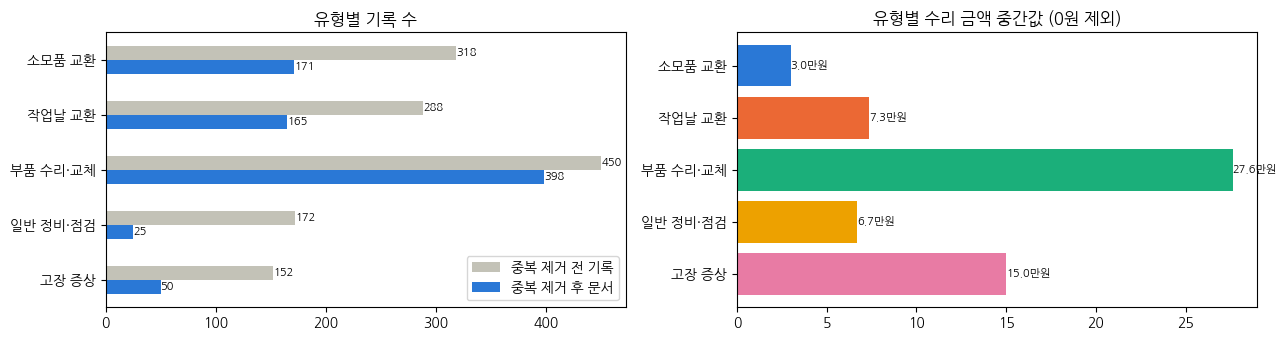

In [7]:
import matplotlib.pyplot as plt     # 그래프 그리는 도구
import koreanize_matplotlib         # 불러오기만 하면 그래프 한글 글꼴(나눔고딕)이 설정됨

# 유형 순서와 유형별 색 (아래 모든 그래프에서 똑같이 사용)
ORDER = ["소모품 교환", "작업날 교환", "부품 수리·교체", "일반 정비·점검", "고장 증상"]
COLORS = dict(zip(ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))   # {유형: 색} 사전

# 그림 2칸 (왼쪽: 문서 수, 오른쪽: 금액)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))

# (왼쪽) 중복 제거 전 기록 수 vs 중복 제거 후 문서 수
both = pd.DataFrame({"중복 제거 전 기록": merged["유형"].value_counts(),
                     "중복 제거 후 문서": data["유형"].value_counts()}).reindex(ORDER)
both.plot.barh(ax=axes[0], color=["#c3c2b7", "#2a78d6"])
for bars in axes[0].containers:                      # 막대 묶음마다
    axes[0].bar_label(bars, fontsize=8)              # 막대 끝에 숫자 표시
axes[0].invert_yaxis()                               # 위에서부터 ORDER 순서대로
axes[0].set_title("유형별 기록 수")
axes[0].set_ylabel("")

# (오른쪽) 유형별 수리 금액 중간값 — 금액이 0원(자가정비·무상)인 기록은 빼고, 중복 제거 전 전체 기록으로 계산
paid = merged[merged["금액"] > 0]
median_cost = paid.groupby("유형")["금액"].median().reindex(ORDER) / 10000   # 원 → 만원
axes[1].barh(ORDER, median_cost, color=[COLORS[k] for k in ORDER])
axes[1].bar_label(axes[1].containers[0], fmt="%.1f만원", fontsize=8)
axes[1].invert_yaxis()
axes[1].set_title("유형별 수리 금액 중간값 (0원 제외)")
plt.tight_layout()
plt.show()

✅ **결과 확인:**
- 중복을 지우자 **일반 정비·점검**이 크게 줄었습니다. `정비`라는 같은 말만 반복해서 적었기 때문입니다. 남은 문서가 적어서 이 유형은 맞히기 어렵습니다.
- 금액은 **부품 수리·교체**와 **고장 증상**이 높습니다. 증상만 적힌 기록은 큰 고장이라 업체에 맡긴 경우가 많은 것으로 보입니다(기록만으로는 확인할 수 없음).
- 중간값을 쓴 이유: 몇백만 원짜리 큰 수리 몇 건 때문에 평균이 크게 부풀려지기 때문입니다.

---
## 3. 텍스트 분석: 분류 모델 학습

### 3-1. 학습용 / 평가용 나누기
- 80%는 학습용, 20%는 평가용 (`stratify`: 유형 비율을 똑같이, `random_state`: 매번 같게)
- 단어 단위와 글자 단위를 공평하게 비교하려고 **같은 문서 번호**로 나눕니다.

In [8]:
from sklearn.model_selection import train_test_split

# 문서 번호(data.index)와 정답(유형)을 함께 나눔 → 나중에 '문서' 열과 '단어' 열을 같은 번호로 꺼내 쓸 수 있음
train_idx, test_idx, y_train, y_test = train_test_split(
    data.index, data["유형"], test_size=0.2, random_state=42, stratify=data["유형"])

print("학습용:", len(train_idx), " 평가용:", len(test_idx))
print(y_test.value_counts().reindex(ORDER))

학습용: 647  평가용: 162
유형
소모품 교환      34
작업날 교환      33
부품 수리·교체    80
일반 정비·점검     5
고장 증상       10
Name: count, dtype: int64


### 3-2. 단어 단위 vs 글자 단위 TF-IDF
| 방식 | 입력 | 예: `로터리칼교환` |
|---|---|---|
| **단어 단위** | 1단계에서 Kiwi로 나눈 단어 | `로터리` `칼` `교환` |
| **글자 단위** (char n-gram) | 띄어쓰기 안에서 글자 2~3개씩 겹치게 자른 조각 | `로터` `터리` `리칼` `칼교` `교환` `로터리` `터리칼` … |

글자 단위는 형태소 분석이 필요 없어서 **붙여 쓰기·오타에 강하지만**, 조각 하나하나의 뜻을 설명하기는 어렵습니다.

### 3-3. 4가지 조합 비교 (교차 검증)
평가용이 160개 남짓이라, 한 번 나눈 점수는 **운에 따라 크게 흔들립니다.** 그래서 학습용 안에서 **5겹 교차 검증**(5번 나눠서 평균)으로 비교합니다.

| 용어 | 뜻 |
|---|---|
| 파이프라인 (`make_pipeline`) | 'TF-IDF로 바꾸기 → 모델 학습'을 한 덩어리로 묶음. 교차 검증 때 TF-IDF도 학습 조각에만 맞춰져서 시험 문제를 미리 보는 일이 없음 |
| 교차 검증 (`cross_val_score`) | 학습용을 5조각으로 나눠, 4조각으로 학습하고 1조각으로 채점하기를 5번 반복 |
| macro-F1 | 유형마다 F1을 구해 **똑같은 비중으로 평균** → 적은 유형(일반 정비·점검)도 똑같이 중요하게 봄 |

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold

# 비교할 조합 4개: {이름: (입력으로 쓸 열, 파이프라인)}
#   analyzer=str.split                      : 단어 단위 (이미 띄어쓰기로 나눈 단어 사용)
#   analyzer="char_wb", ngram_range=(2, 3)  : 글자 단위 (띄어쓰기 안에서 2~3글자씩)
#   class_weight="balanced"                 : 개수가 적은 유형을 틀리면 더 크게 벌점
combos = {
    "단어 + 나이브 베이즈": ("단어", make_pipeline(TfidfVectorizer(analyzer=str.split), MultinomialNB())),
    "단어 + 로지스틱 회귀": ("단어", make_pipeline(TfidfVectorizer(analyzer=str.split),
                                               LogisticRegression(max_iter=1000, class_weight="balanced"))),
    "글자 + 나이브 베이즈": ("문서", make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3)), MultinomialNB())),
    "글자 + 로지스틱 회귀": ("문서", make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3)),
                                               LogisticRegression(max_iter=1000, class_weight="balanced"))),
}

# 5겹 교차 검증 방법 (shuffle=True: 섞어서 나눔, 유형 비율은 조각마다 똑같이)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 조합마다 학습용으로 교차 검증 → 정확도·macro-F1 평균
rows = []
for name, (col, pipe) in combos.items():
    X = data.loc[train_idx, col]                                         # 학습용 문서(또는 단어)
    acc = cross_val_score(pipe, X, y_train, cv=cv, scoring="accuracy").mean()
    f1 = cross_val_score(pipe, X, y_train, cv=cv, scoring="f1_macro").mean()
    rows.append({"조합": name, "정확도": round(acc, 3), "macro-F1": round(f1, 3)})

scores = pd.DataFrame(rows)
scores

,조합,정확도,macro-F1
0,단어 + 나이브 베이즈,0.778,0.525
1,단어 + 로지스틱 회귀,0.805,0.771
2,글자 + 나이브 베이즈,0.804,0.558
3,글자 + 로지스틱 회귀,0.867,0.845


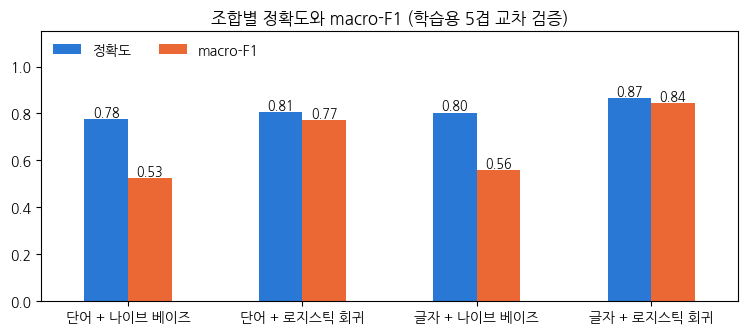

최종 모델: 글자 + 로지스틱 회귀


In [10]:
# 조합별 정확도와 macro-F1 막대그래프 (ylim: 위쪽에 범례 자리 남기기)
ax = scores.set_index("조합").plot.bar(color=["#2a78d6", "#eb6834"], figsize=(9, 3.5), rot=0, ylim=(0, 1.15))
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", fontsize=9)       # 막대 위에 소수 둘째 자리 숫자
ax.set_xlabel("")
ax.set_title("조합별 정확도와 macro-F1 (학습용 5겹 교차 검증)")
ax.legend(loc="upper left", ncol=2, frameon=False)
plt.show()

# macro-F1이 가장 높은 조합을 최종 모델로 고르고, 학습용 전체로 다시 학습
best_name = scores.sort_values("macro-F1", ascending=False)["조합"].iloc[0]
best_col, best = combos[best_name]
best.fit(data.loc[train_idx, best_col], y_train)
print("최종 모델:", best_name)

✅ **결과 확인:**
- 나이브 베이즈는 정확도에 비해 macro-F1이 낮습니다. 개수가 적은 유형을 거의 못 맞히기 때문입니다.
- 단어 단위와 글자 단위 중 어느 쪽이 나은가요? 기록이 짧고 붙여 쓴 말이 많을수록 **글자 단위가 유리**한 경우가 많습니다.

---
## 4. 분석 결과
| 번호 | 결과 |
|---|---|
| 4-1 | 평가용 성적표 (정밀도·재현율·F1) |
| 4-2 | 혼동 행렬 |
| 4-3 | 유형별 핵심 표현 |
| 4-4 | 틀린 문서 직접 읽기 |
| 4-5 | 연도별 정비 유형 변화 |
| 4-6 | 새 기록 넣어 보기 |

### 4-1. 평가용 성적표
지금까지 한 번도 쓰지 않은 **평가용 20%**로 최종 점수를 냅니다.

In [11]:
from sklearn.metrics import classification_report

# 최종 모델로 평가용 문서 예측
pred = best.predict(data.loc[test_idx, best_col])

# 유형별 성적표 (labels=ORDER: 유형 순서 고정, digits=3: 소수 셋째 자리)
print(classification_report(y_test, pred, labels=ORDER, digits=3))

              precision    recall  f1-score   support

      소모품 교환      0.811     0.882     0.845        34
      작업날 교환      0.879     0.879     0.879        33
    부품 수리·교체      0.893     0.838     0.865        80
    일반 정비·점검      0.500     0.600     0.545         5
       고장 증상      0.818     0.900     0.857        10

    accuracy                          0.852       162
   macro avg      0.780     0.820     0.798       162
weighted avg      0.856     0.852     0.853       162



| 지표 | 뜻 (예: 작업날 교환) |
|---|---|
| 정밀도 (precision) | 모델이 '작업날 교환'이라고 한 것 중 진짜 작업날 교환 비율 |
| 재현율 (recall) | 진짜 작업날 교환 중 모델이 찾아낸 비율 |
| support | 평가용에 있는 그 유형의 문서 수 |

### 4-2. 혼동 행렬

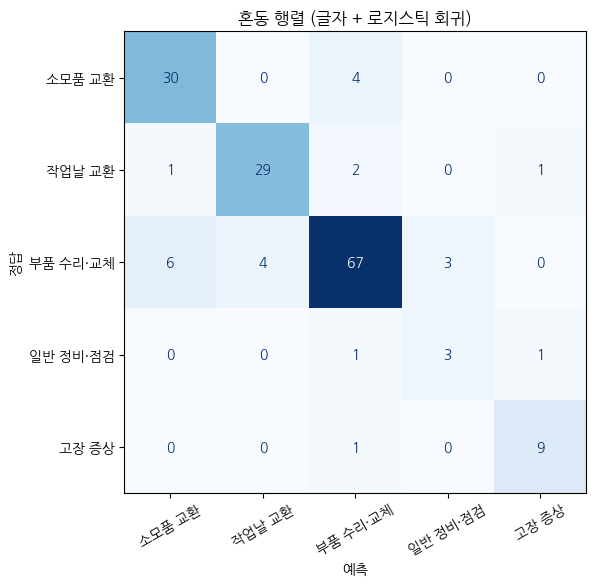

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

# 가로 = 예측, 세로 = 정답, 대각선 = 맞힌 문서 수 (colorbar=False: 색 막대 숨기기)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=ORDER, cmap="Blues",
                                        colorbar=False, ax=ax, xticks_rotation=30)
ax.set_xlabel("예측")
ax.set_ylabel("정답")
ax.set_title(f"혼동 행렬 ({best_name})")
plt.show()

✅ **결과 확인:** 대각선 밖에서 숫자가 큰 칸을 찾아보세요. '부품 수리·교체'는 다른 유형 단어(`오일`, `벨트`, `날`)와 부품 이름이 **한 기록에 섞여 있는 경우**가 많아서 헷갈리기 쉽습니다. '부품 수리·교체'를 '일반 정비·점검'으로 틀렸다면, `교류발전기조합 정비`처럼 부품 이름 뒤에 `정비`라는 말이 붙은 기록 때문일 수 있습니다.





### 4-3. 틀린 문서 직접 읽기

In [14]:
# 평가용 문서의 원문·정리된 문서·정답에 예측을 붙인 표
result = data.loc[test_idx, ["ID", "원문", "문서", "유형"]].assign(예측=pred)

# 정답과 예측이 다른 문서만
wrong = result[result["유형"] != result["예측"]]
print(f"틀린 문서: {len(wrong)}개 / {len(result)}개")

# 긴 원문도 60글자까지 보이게 설정한 뒤 앞 10개 보기
pd.set_option("display.max_colwidth", 60)
wrong[["원문", "유형", "예측"]].head(10)

틀린 문서: 24개 / 162개


,원문,유형,예측
791,전선 탈부착요령 검은선 -+ 흰선 + (확인요망),일반 정비·점검,고장 증상
565,엔진오일외 8종 수리 교체 0.하부로라1개+ 0.경유20l 1통+ 0.오일휠터 1개+ 0.밧데리 1개...,부품 수리·교체,소모품 교환
448,에어크리너외12종 엔진오일9리터 .엔진필터.핸들엑셀와이어.유압필터.유압오일68리터.필터엘리먼트조합.연...,부품 수리·교체,소모품 교환
21,부품교환,일반 정비·점검,부품 수리·교체
125,오일펌프교환 유압펌프교환유압오일보충,부품 수리·교체,일반 정비·점검
771,점화코일+플러그+유압밸트교환 점화코일(2EA)+ 플러그(2EA)+ 유압밸트B34(1EA) 교환,부품 수리·교체,소모품 교환
786,2차 풍구밸트(콩출구) 교환 2차 풍구밸트(콩출구) 1EA 교환,소모품 교환,부품 수리·교체
327,밸트외 1종 밸트B59 2개클러치와이어 1개,부품 수리·교체,소모품 교환
800,기화기 교환 기화기 교환,부품 수리·교체,일반 정비·점검
795,콤바인수리 오일필터외24종,소모품 교환,부품 수리·교체


✅ **결과 확인:** 틀린 이유를 세 가지로 나눠 보세요.
1. **모델이 틀림** (유형을 알 수 있는 단어가 있는데 틀림)
2. **기록만으로는 알 수 없음** (`수리 교환`, `부품교환`처럼 내용이 없음)
3. **정답이 의심스러움** (사람이 정한 정답이 틀렸을 수도 있음)

### 4-5. 연도별 정비 유형 변화
정답이 붙은 **전체 기록**(중복 제거 전)으로 연도별 유형 비율을 봅니다. 분류 모델이 잘 맞는다면, 앞으로 정답이 없는 새 기록도 이렇게 집계할 수 있습니다.

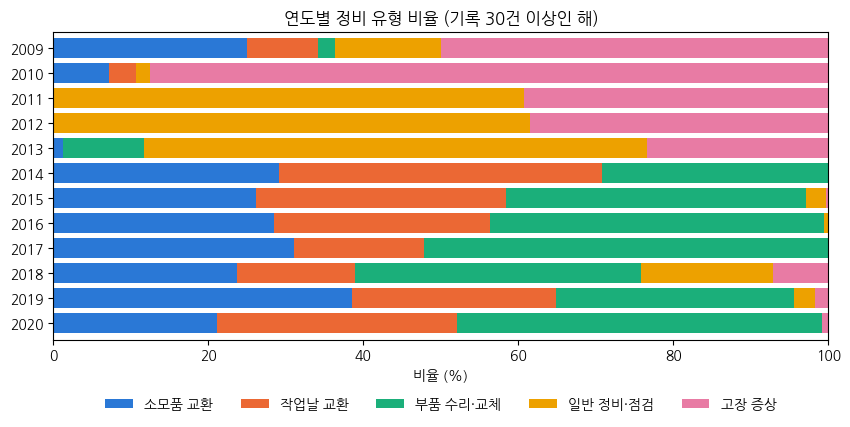

{'2009': 44, '2010': 56, '2011': 56, '2012': 52, '2013': 77, '2014': 48, '2015': 279, '2016': 190, '2017': 90, '2018': 211, '2019': 114, '2020': 123}


In [15]:
# 수리일자 앞 4글자 = 연도
merged["연도"] = merged["수리일자"].str[:4]

# 연도 × 유형 개수 표 (crosstab: 두 열의 조합별 개수) → ORDER 순서로
table = pd.crosstab(merged["연도"], merged["유형"])[ORDER]

# 기록이 30건 이상인 연도만 (기록이 적은 해는 비율이 크게 흔들림)
table = table[table.sum(axis=1) >= 30]

# 개수 → 연도별 비율(%) (div: 행마다 합계로 나누기)
ratio = table.div(table.sum(axis=1), axis=0) * 100

# 누적 가로 막대
ax = ratio.plot.barh(stacked=True, color=[COLORS[k] for k in ORDER], figsize=(10, 4), width=0.8)
ax.invert_yaxis()                                         # 위에서부터 오래된 연도
ax.set_xlabel("비율 (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.set_title("연도별 정비 유형 비율 (기록 30건 이상인 해)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=5, frameon=False)   # 범례를 그래프 아래에
plt.show()

# 연도별 기록 수도 함께 보기
print(table.sum(axis=1).to_dict())

✅ **결과 확인:** 2013년까지는 '고장 증상'과 '일반 정비·점검'이 대부분이고, 2014년부터는 소모품·작업날·부품 유형이 대부분입니다. 고장이 갑자기 줄었다기보다는, **기록하는 방식이 바뀐 것**(예전에는 `작동불량`, `정비`처럼 짧게 적다가 나중에는 교체한 부품까지 적음)으로 보는 것이 자연스럽습니다. 이처럼 분류 결과를 집계할 때는 **기록 방식의 변화**를 먼저 의심해야 합니다.

### 4-6. 새 기록 넣어 보기
**✏️ [입력]** 수리 기록을 바꿔 보세요. 새 기록도 **1단계와 같은 정제 함수**를 거칩니다.

In [16]:
# ===== ✏️ [입력] 새 수리 기록 =====
new_records = [
    "엔진오일 및 휠타 교환",
    "로타리칼 24개 교환",
    "유압호스 파손으로 교환",
    "시동이 안걸림",
    "정기점검",
]
# ================================

# 새 기록 정제 → (단어 단위 모델이면 단어 나누기까지) → 최종 모델에 넣기
new_docs = [clean(r) for r in new_records]
if best_col == "단어":
    new_docs = [to_words(d) for d in new_docs]

# 유형별 확률 표 (행 = 기록, 열 = 유형, 값 = %)
proba = pd.DataFrame(best.predict_proba(new_docs) * 100, columns=best.classes_, index=new_records)[ORDER].round(1)
proba.insert(0, "예측 유형", proba.idxmax(axis=1))       # 확률이 가장 큰 유형을 맨 앞 열에
proba

,예측 유형,소모품 교환,작업날 교환,부품 수리·교체,일반 정비·점검,고장 증상
엔진오일 및 휠타 교환,소모품 교환,82.8,3.0,5.8,6.3,2.1
로타리칼 24개 교환,작업날 교환,5.0,84.9,5.7,2.2,2.2
유압호스 파손으로 교환,부품 수리·교체,11.9,12.7,54.3,7.9,13.2
시동이 안걸림,부품 수리·교체,11.8,13.3,35.4,6.3,33.3
정기점검,일반 정비·점검,4.9,6.2,11.5,70.4,7.0


✅ **결과 확인:** `시동이 안걸림`처럼 기록에 거의 나오지 않는 말투(기록에는 주로 `시동불량`)는 확률이 낮게 나오고 틀릴 수도 있습니다. 모델은 **학습 데이터에 있던 표현**만 압니다.

In [17]:
# 평가용 문서별 정답과 예측 저장
result.to_csv("predictions.csv", index=False, encoding="utf-8-sig")
print("저장 완료: repair_dataset.csv, predictions.csv")

저장 완료: repair_dataset.csv, predictions.csv


---
## 정리

### ✅ 한 줄 정리
**짧고 제각각인 수리 기록을 표기 통일·정제한 뒤, 단어 단위와 글자 단위 TF-IDF로 바꿔 분류 모델을 비교하고 정비 유형을 자동으로 나눴다.**

### 🗂️ 만든 파일
| 파일 | 내용 |
|---|---|
| `repair_dataset.csv` | 정제 데이터셋 (ID, 원문, 문서, 단어, 유형) |
| `predictions.csv` | 평가용 문서의 정답과 예측 |

### 🤔 생각해 볼 점 (한계)
| 한계 | 설명 |
|---|---|
| **정답이 사람 한 명의 판단** | 여러 사람이 정답을 달고 일치하는지 확인하는 것이 더 믿을 만합니다. |
| **유형 기준이 섞여 있음** | 소모품·작업날·부품은 '무엇을 고쳤나', 고장 증상은 '왜 왔나', 일반 정비는 '내용이 없는 기록'입니다. 기준을 하나로 맞추면(예: 부품 기준 3개 + 기타) 결과가 달라집니다. |
| **데이터가 작음** | 중복을 지우면 약 810개뿐이고, '일반 정비·점검'은 30개도 안 됩니다. 평가용 점수는 몇 문서만 바뀌어도 크게 흔들립니다. |
| **표기 통일의 효과** | 표기 통일은 사람이 읽고 집계하기에는 확실히 도움이 됩니다. 하지만 **분류 점수**에 주는 효과는 이 데이터에서 작았습니다(특히 글자 단위는 `밸트`와 `벨트`가 `트` 조각을 공유해서 스스로 어느 정도 흡수함). |
| **기록 품질이 상한선** | `정비`, `수리 교환`처럼 내용 없는 기록은 어떤 모델도 제대로 나눌 수 없습니다. 자동 분류보다 **기록 양식 개선**이 먼저일 수 있습니다. |
| **기종 정보 없음** | `기종관리번호`가 어떤 기계인지 대응표가 없어서, 기계 종류별 분석은 할 수 없었습니다. |



**참고:** [Kiwi (kiwipiepy)](https://github.com/bab2min/kiwipiepy) · [scikit-learn 텍스트 특징 추출](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction) · [scikit-learn 교차 검증](https://scikit-learn.org/stable/modules/cross_validation.html)